# Isosurfaces

Isosurfaces (`&ISOF`) are surfaces of constant value, for example where the temperature is
60 °C, written as triangles at every output time.

Run FDS on `fds_steckler/input_steckler.fds` first: the Steckler room with temperature
isosurfaces at 10, 30 and 60 °C.

In [1]:
import pyvista as pv

import fdsreader as fds

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

In [2]:
sim = fds.Simulation("./fds_steckler")
sim.isosurfaces

IsosurfaceCollection([Isosurface(id="1", quantity=Quantity('TEMPERATURE'), levels=[[10.0 30.0 60.0]]),
Isosurface(id="2", quantity=Quantity('U-VELOCITY'), levels=[[0.07999999821186066]])])

## One output time

`to_global` returns the vertices of all meshes, a triangle array per level and, if FDS
wrote it, colour data. A level whose value is never reached has no triangles.

In [3]:
iso = sim.isosurfaces.filter_by_quantity("TEMPERATURE")[0]
t = iso.get_nearest_timestep(60.0)
vertices, triangles, _ = iso.to_global(t)

levels = iso.levels[0]
for level, tri in zip(levels, triangles):
    print(f"{level:5.1f} C: {len(tri)} triangles")

 10.0 C: 0 triangles
 30.0 C: 6550 triangles
 60.0 C: 1934 triangles


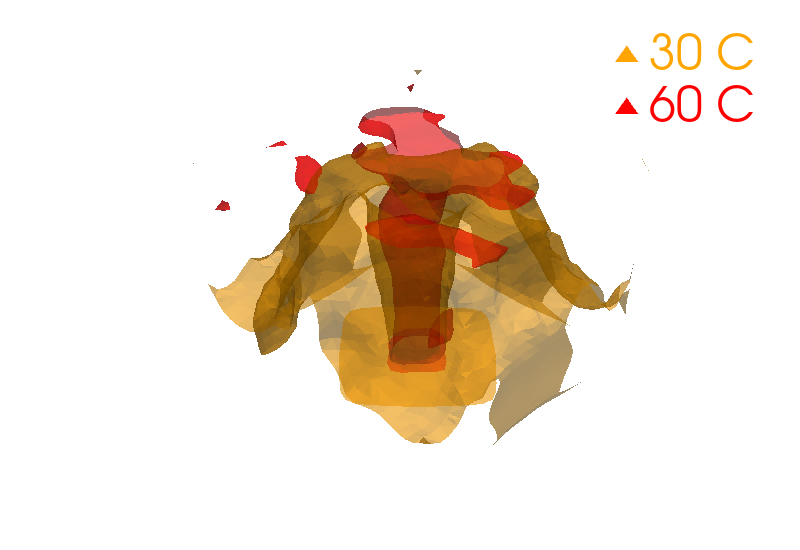

In [4]:
colors = {30.0: "orange", 60.0: "red"}
plotter = pv.Plotter()
for level, tri in zip(levels, triangles):
    if len(tri) and level in colors:
        plotter.add_mesh(iso.get_pyvista_mesh(vertices, tri), color=colors[level], opacity=0.6, label=f"{level:.0f} C")
plotter.add_legend()
plotter.show()

`iso.export(...)` writes such a mesh to a file. More in the
[API reference](https://fdsreader.readthedocs.io/en/latest/api/isof.html).